<a href="https://colab.research.google.com/github/Saransh-Basu-01/50-Ml-Projects-to-understand-LLMs/blob/main/Project_28_Effective_Dimensionality_of_Hidden_Layers.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:

import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm

import requests

import torch
from transformers import AutoModelForCausalLM, AutoTokenizer

# Concept of Effective Dimensionality

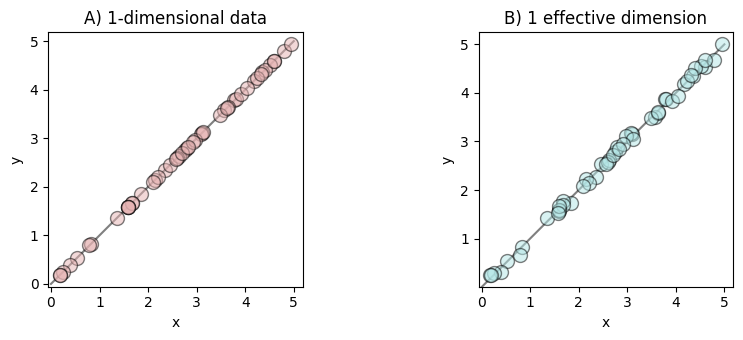

In [4]:
# a bit of data
x = np.random.uniform(low=0,high=5,size=50)
y = np.random.normal(loc=0,scale=.07,size=len(x))

_,axs = plt.subplots(1,2,figsize=(9,3.5))
axs[0].plot(x,x,'ko',markerfacecolor=[.9,.7,.7,.5],markersize=10)
axs[1].plot(x,x+y,'ko',markerfacecolor=[.7,.9,.9,.5],markersize=10)

for a in axs:
  a.axis('square')
  a.plot([0,5],[0,5],color='gray',zorder=-2)

axs[0].set(xlabel='x',ylabel='y',title='A) 1-dimensional data')
axs[1].set(xlabel='x',ylabel='y',title='B) 1 effective dimension')

plt.tight_layout()
plt.show()

# Part_1:Logits form real and shuffled token sequences

## Task_1:
- Import GPT-2-xl and its tokenizer. Toggle the model into eval
mode and move it to the GPU. Define a variable that encodes the
maximum context window size, which is the maximum number of
tokens the model can process at once. Hint: check model.config.
Import and tokenize the text for Through the Looking Glass
from gutenberg.org (see Chapter 2). Extract a max-token-sequence
length vector of tokens starting in the middle of the book. Print out
the tokens and enjoy reading a snippet of Alice’s adventures :)
Create a copy of the token sequence variable with randomly
shuffled tokens. Thus, you should now have two PyTorch tensors of
tokens to push through the model: One tensor is real tokens from
the text, and the other is the same tokens but in a randomly shuffled
order. Print those tokens.

In [7]:
tokenizer=AutoTokenizer.from_pretrained('gpt2-xl')
model=AutoModelForCausalLM.from_pretrained('gpt2-xl')
model.eval()

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/580 [00:00<?, ?it/s]

GPT2LMHeadModel(
  (transformer): GPT2Model(
    (wte): Embedding(50257, 1600)
    (wpe): Embedding(1024, 1600)
    (drop): Dropout(p=0.1, inplace=False)
    (h): ModuleList(
      (0-47): 48 x GPT2Block(
        (ln_1): LayerNorm((1600,), eps=1e-05, elementwise_affine=True, bias=True)
        (attn): GPT2Attention(
          (c_attn): Conv1D(nf=4800, nx=1600)
          (c_proj): Conv1D(nf=1600, nx=1600)
          (attn_dropout): Dropout(p=0.1, inplace=False)
          (resid_dropout): Dropout(p=0.1, inplace=False)
        )
        (ln_2): LayerNorm((1600,), eps=1e-05, elementwise_affine=True, bias=True)
        (mlp): GPT2MLP(
          (c_fc): Conv1D(nf=6400, nx=1600)
          (c_proj): Conv1D(nf=1600, nx=6400)
          (act): NewGELUActivation()
          (dropout): Dropout(p=0.1, inplace=False)
        )
      )
    )
    (ln_f): LayerNorm((1600,), eps=1e-05, elementwise_affine=True, bias=True)
  )
  (lm_head): Linear(in_features=1600, out_features=50257, bias=False)
)

In [6]:
device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
device

device(type='cuda', index=0)

In [8]:
model.config

GPT2Config {
  "activation_function": "gelu_new",
  "add_cross_attention": false,
  "architectures": [
    "GPT2LMHeadModel"
  ],
  "attn_pdrop": 0.1,
  "bos_token_id": 50256,
  "dtype": "float32",
  "embd_pdrop": 0.1,
  "eos_token_id": 50256,
  "initializer_range": 0.02,
  "layer_norm_epsilon": 1e-05,
  "model_type": "gpt2",
  "n_ctx": 1024,
  "n_embd": 1600,
  "n_head": 25,
  "n_inner": null,
  "n_layer": 48,
  "n_positions": 1024,
  "output_past": true,
  "pad_token_id": null,
  "reorder_and_upcast_attn": false,
  "resid_pdrop": 0.1,
  "scale_attn_by_inverse_layer_idx": false,
  "scale_attn_weights": true,
  "summary_activation": null,
  "summary_first_dropout": 0.1,
  "summary_proj_to_labels": true,
  "summary_type": "cls_index",
  "summary_use_proj": true,
  "task_specific_params": {
    "text-generation": {
      "do_sample": true,
      "max_length": 50
    }
  },
  "tie_word_embeddings": true,
  "transformers_version": "5.22.1",
  "use_cache": true,
  "vocab_size": 50257
}

In [10]:
max_seq_len =model.config.n_ctx

model.to(device)

GPT2LMHeadModel(
  (transformer): GPT2Model(
    (wte): Embedding(50257, 1600)
    (wpe): Embedding(1024, 1600)
    (drop): Dropout(p=0.1, inplace=False)
    (h): ModuleList(
      (0-47): 48 x GPT2Block(
        (ln_1): LayerNorm((1600,), eps=1e-05, elementwise_affine=True, bias=True)
        (attn): GPT2Attention(
          (c_attn): Conv1D(nf=4800, nx=1600)
          (c_proj): Conv1D(nf=1600, nx=1600)
          (attn_dropout): Dropout(p=0.1, inplace=False)
          (resid_dropout): Dropout(p=0.1, inplace=False)
        )
        (ln_2): LayerNorm((1600,), eps=1e-05, elementwise_affine=True, bias=True)
        (mlp): GPT2MLP(
          (c_fc): Conv1D(nf=6400, nx=1600)
          (c_proj): Conv1D(nf=1600, nx=6400)
          (act): NewGELUActivation()
          (dropout): Dropout(p=0.1, inplace=False)
        )
      )
    )
    (ln_f): LayerNorm((1600,), eps=1e-05, elementwise_affine=True, bias=True)
  )
  (lm_head): Linear(in_features=1600, out_features=50257, bias=False)
)

In [11]:
text = requests.get('https://www.gutenberg.org/cache/epub/11/pg11.txt').text

In [23]:
allTokens =tokenizer.encode(text,return_tensors='pt')

# get context-length from middle of the book
start_idx =len(allTokens[0])//2
end_idx =start_idx + max_seq_len

tokens = allTokens[:,start_idx:end_idx]

print(tokenizer.decode(tokens[0]))

 three little sisters,” the Dormouse began
in a great hurry; “and their names were Elsie, Lacie, and Tillie; and
they lived at the bottom of a well—”

“What did they live on?” said Alice, who always took a great interest
in questions of eating and drinking.

“They lived on treacle,” said the Dormouse, after thinking a minute or
two.

“They couldn’t have done that, you know,” Alice gently remarked;
“they’d have been ill.”

“So they were,” said the Dormouse; “_very_ ill.”

Alice tried to fancy to herself what such an extraordinary way of
living would be like, but it puzzled her too much, so she went on: “But
why did they live at the bottom of a well?”

“Take some more tea,” the March Hare said to Alice, very earnestly.

“I’ve had nothing yet,” Alice replied in an offended tone, “so I can’t
take more.”

“You mean you can’t take _less_,” said the Hatter: “it’s very easy to
take _more_ than nothing.”

“Nobody asked _your_ opinion,” said Alice.

“Who’s making personal remarks now?” the Hatte

In [21]:
allTokens.shape

torch.Size([1, 52948])

In [22]:
allTokens[:,start_idx:end_idx].shape

torch.Size([1, 1024])

In [29]:
tokensShuffle = tokens[0,torch.randperm(len(tokens[0]))].unsqueeze(0)
print(tokenizer.decode(tokensShuffle[0]))

 plate way hurry
,��

�ouse sisters
? water youAlice D the� a can to�ing,c D yetd,
:This milk March March you�, bread did
 theatter know� and more
 little�and� it in-
�,
 began verysome� again� should� so oft
s the at civil draw a this mean the totwo theyplace out_, and him as tre draw�
 asked the
orm change theage�antlyily
to� great the the all, did letit lived�� Alice”your� March Alice interrupt
 more�
—
 tea� whatouse know done� did
He than began answer some _ � a and one D yous she�.�. a said againacle off on finish�
 at of Lac� to�ormtulkorm
from:
 Alice to— of
theym and earnest personalatter at� she
 moved fromorm� �
� toon to, said were Datter had
�There theso Aliceouse confused
 these went- treHouse the �



so_.�, interruptedWhatorm anin, time lived�� dealve her just�,

 three unw
 the the couldnorm remarksyou� turnedie�,,
�_ andYouandacle
 the;
 oflet
�. the� think the live said canouse D their
 I interrupt�
 go: said a
,. into stupid�

 makingiously
Tre�
 I may El
If; was D


## Task_2:
- Push both tensors of tokens through the model in separate runs to
create separate output variables for the real and shuffled tokens.
Export the hidden-state vectors, and check the sizes of the hidden
state activations. Determine the number of singular values in each
hidden-state activations matrix based on my description of the SVD
at the outset of this project.
Transform the output logits to log-softmax. Thus far in the
book, I’ve been using the PyTorch function log_softmax. Here, use
the method .log_softmax.
Find and store the maximum log-softmax value for each of
1024 tokens, separately for the real and shuffled token sequences.
Then visualize the histograms of those max-log-softmax values as in
Figure 5.26

In [37]:
with torch.no_grad():
  outputs_real = model(tokens.to(device),output_hidden_states=True)
  outputs_shuf = model(tokensShuffle.to(device),output_hidden_states=True)

outputs_real.hidden_states[0].shape

torch.Size([1, 1024, 1600])

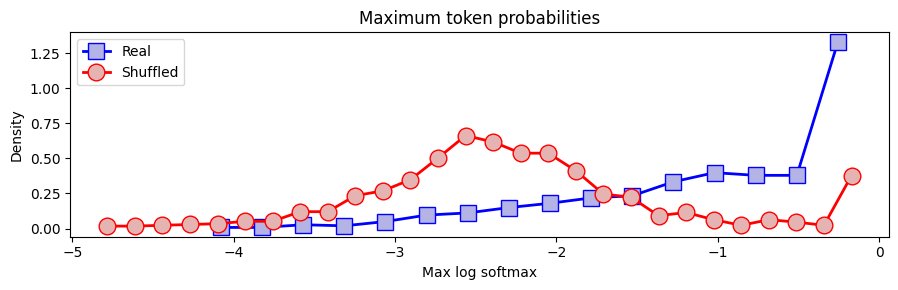

In [38]:
# calculate log-softmax of logits (note the method instead of function)
log_sm_real = outputs_real.logits.log_softmax(dim=-1).cpu()
log_sm_shuf = outputs_shuf.logits.log_softmax(dim=-1).cpu()

# find the indices of the max log-sm values
maxidx = torch.argmax(log_sm_real,dim=-1).squeeze()

# then find the actual log-sm values from those indices
maxvals = [log_sm_real[0,i,maxidx[i]].item() for i in range(len(maxidx))]

# and calculate the histogram
yReal,xReal = np.histogram(maxvals,bins='fd',density=True)


### repeat for shuffled
maxidx = torch.argmax(log_sm_shuf,dim=-1).squeeze()
maxvals = [log_sm_shuf[0,i,maxidx[i]].item() for i in range(len(maxidx))]
yShuf,xShuf = np.histogram(maxvals,bins='fd',density=True)


# visualize
plt.figure(figsize=(9,3))
plt.plot(xReal[:-1],yReal,'bs-',markerfacecolor=[.7,.7,.9],markersize=12,linewidth=2,label='Real')
plt.plot(xShuf[:-1],yShuf,'ro-',markerfacecolor=[.9,.7,.7],markersize=12,linewidth=2,label='Shuffled')

plt.gca().set(xlabel='Max log softmax',ylabel='Density',title='Maximum token probabilities')
plt.legend()

plt.tight_layout()
plt.show()

# Part 2: Effective dimensionality in one layer (NumPy)

## Task_1:
- Choose one hidden layer to focus on (I used layer 10). Extract the
activations from that layer, and convert the PyTorch tensor into a
2D NumPy array. NumPy isn’t designed to operate on GPUs, so you
need to transfer the hidden-state tensors to the CPU. You can focus
only on the real-ordered tokens here; we’ll use the shuffled tokens
later.
Mean-center the data token-wise, such that the mean of each
hidden-state vector is zero. Calculate the SVD to get a vector
of singular values. Transform the raw singular values to percent
variance explained using Equation 5.3 (the singular values squared,
divided by the sum of the squared singular values), and then to
cumulative percent explained.
Visualize the percent variance explained and cumulative vari
ance explained as in Figure 5.27. The dashed gray lines indicate the
total variance explained by the first 50 components

In [45]:
A = np.array([
    [1, 2],
    [3, 4],
    [5, 6]
])

# Compute Full SVD
np.linalg.svd(A)[1]

array([9.52551809, 0.51430058])

In [46]:
np.linalg.svd(A)

SVDResult(U=array([[-0.2298477 ,  0.88346102,  0.40824829],
       [-0.52474482,  0.24078249, -0.81649658],
       [-0.81964194, -0.40189603,  0.40824829]]), S=array([9.52551809, 0.51430058]), Vh=array([[-0.61962948, -0.78489445],
       [-0.78489445,  0.61962948]]))

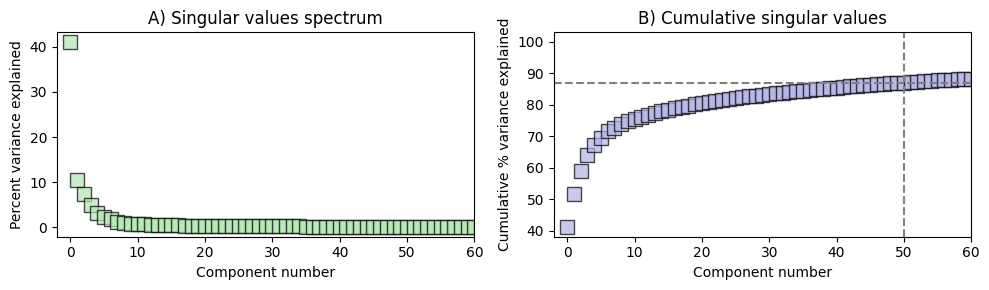

In [49]:

layeri = 10

# extract all the activations from this layer
acts = outputs_real.hidden_states[layeri][0,:,:].cpu().numpy()

# mean-center the activations
acts -=acts.mean(axis=0,keepdims=True)

# get singular values
s = np.linalg.svd(acts)[1]

# percent explained (and cumulative)
pctExplained = 100 * s**2 / np.sum(s**2)
cumVarExplained = np.cumsum(pctExplained)


_,axs = plt.subplots(1,2,figsize=(10,3))

axs[0].plot(pctExplained,'ks',markersize=10,markerfacecolor=[.7,.9,.7,.7])
axs[0].set(xlim=[-2,60],xlabel='Component number',ylabel='Percent variance explained',
           title='A) Singular values spectrum')

axs[1].plot(cumVarExplained,'ks',markersize=10,markerfacecolor=[.7,.7,.9,.7])
axs[1].axhline(cumVarExplained[50],linestyle='--',color='gray')
axs[1].axvline(50,linestyle='--',color='gray')
axs[1].set(xlim=[-2,60],xlabel='Component number',ylabel='Cumulative % variance explained',
           title='B) Cumulative singular values')

plt.tight_layout()

plt.show()

## Task_2:
- Calculate the “effective dimensionality” as the number of components
it takes to account for 95% of the total variability.

In [50]:
threshold = 95

# count the components until 95% variance is explained
effectiveCompCount = np.where(cumVarExplained>threshold)[0][0]
print(f'{effectiveCompCount} (out of {len(s)}) components explains {cumVarExplained[effectiveCompCount]/100:.2%} variability')

159 (out of 1024) components explains 95.04% variability


# Part 3: Laminar profile of effective dimensionality (PyTorch)

## Task_1:
- In a for-loop over the 49 hidden-state layers, calculate the effective
dimensionality as you did in Part 2, except modify the code to use
PyTorch instead of NumPy. Also calculate and store the matrix rank
of each hidden-states matrix (the “rank” of a matrix is the number
of linearly independent columns in the matrix). Leave the data on
the GPU except for the final results for visualization (Matplotlib
needs the data on the CPU).
Repeat the analysis for the shuffled tokens. You can store these
results in a 49 × 2 PyTorch tensor of integers containing the num
ber of components to account for 95% variability in each hidden layer.
Visualize the matrix ranks as in Figure 5.29.
Calculate the percent of maximum possible dimensionality as
the effective dimensionality count divided by the matrix rank for
each hidden-state layer. Visualize the results as in Figure 5.30.
Note the two y-axis labels: the left axis and the markers shows
effective dimensionality as counts, while the right axis and the lines
shows effective dimensionality as percent of maximum dimensionality
(rank)

In [51]:
numHidden = len(outputs_real.hidden_states)
numHidden

49

In [58]:
# redefine threshold
threshold = 99

# initialize
effectiveCompCount = torch.zeros((numHidden,2),dtype=int)
hs_ranks = torch.zeros((numHidden,2),dtype=int)


# loop over layers
for layeri in tqdm(range(numHidden)):

  # extract all the activations from this layer (assuming no batches!)
  acts = outputs_real.hidden_states[layeri][0,:,:]

  # mean-center the activations and calcuate rank
  acts -=acts.mean(axis=0,keepdims=True)
  hs_ranks[layeri,0] = torch.linalg.matrix_rank(acts).item()

  # get singular values
  s = torch.linalg.svdvals(acts)

  # percent explained (cumulative)
  pctExplained =100 * s**2/torch.sum(s**2)
  cumVarExplained =torch.cumsum(pctExplained,dim=-1).cpu()

  # count the components until 95% variance is explained
  compcount = torch.where(cumVarExplained>threshold)[0][0]
  effectiveCompCount[layeri,0] = compcount



  ### repeat for shuffled tokens
  acts = outputs_shuf.hidden_states[layeri][0,:,:]
  acts -= acts.mean(axis=0,keepdims=True)
  hs_ranks[layeri,1] = torch.linalg.matrix_rank(acts).item()
  s = torch.linalg.svdvals(acts) # get singular values
  pctExplained = 100 * s**2 / torch.sum(s**2) # percent explained
  cumVarExplained = torch.cumsum(pctExplained,dim=-1).cpu() # cumulative
  effectiveCompCount[layeri,1] = torch.where(cumVarExplained>threshold)[0][0]


100%|██████████| 49/49 [00:26<00:00,  1.86it/s]


In [59]:
print(f'There are {len(np.unique(tokens[0]))} out of {len(tokens[0])} unique tokens.')

There are 298 out of 1024 unique tokens.


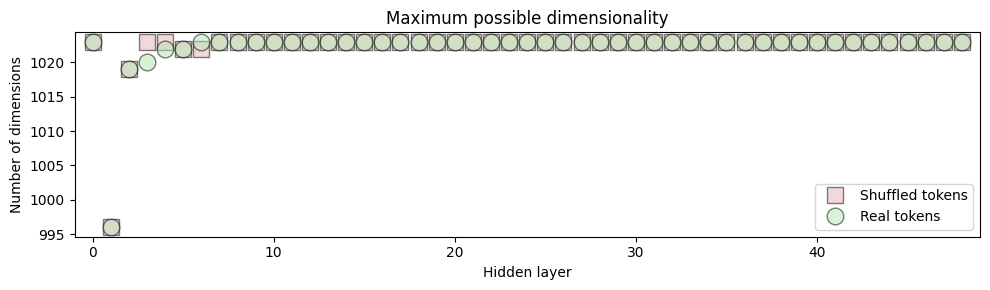

In [60]:
_,ax = plt.subplots(1,figsize=(10,3))

## plot the "effective subspace dimensionality" of each layer
ax.plot(hs_ranks[:,1],'ks',markerfacecolor=[.9,.7,.7,.5],markersize=12,label='Shuffled tokens')
ax.plot(hs_ranks[:,0],'ko',markerfacecolor=[.7,.9,.7,.5],markersize=12,label='Real tokens')
ax.legend()
ax.set(xlabel='Hidden layer',ylabel='Number of dimensions',title='Maximum possible dimensionality',xlim=[-1,numHidden])

plt.tight_layout()
plt.show()


In [56]:

hs_ranks

tensor([[1023, 1023],
        [ 996,  996],
        [1019, 1019],
        [1020, 1023],
        [1022, 1023],
        [1022, 1022],
        [1023, 1022],
        [1023, 1023],
        [1023, 1023],
        [1023, 1023],
        [1023, 1023],
        [1023, 1023],
        [1023, 1023],
        [1023, 1023],
        [1023, 1023],
        [1023, 1023],
        [1023, 1023],
        [1023, 1023],
        [1023, 1023],
        [1023, 1023],
        [1023, 1023],
        [1023, 1023],
        [1023, 1023],
        [1023, 1023],
        [1023, 1023],
        [1023, 1023],
        [1023, 1023],
        [1023, 1023],
        [1023, 1023],
        [1023, 1023],
        [1023, 1023],
        [1023, 1023],
        [1023, 1023],
        [1023, 1023],
        [1023, 1023],
        [1023, 1023],
        [1023, 1023],
        [1023, 1023],
        [1023, 1023],
        [1023, 1023],
        [1023, 1023],
        [1023, 1023],
        [1023, 1023],
        [1023, 1023],
        [1023, 1023],
        [1

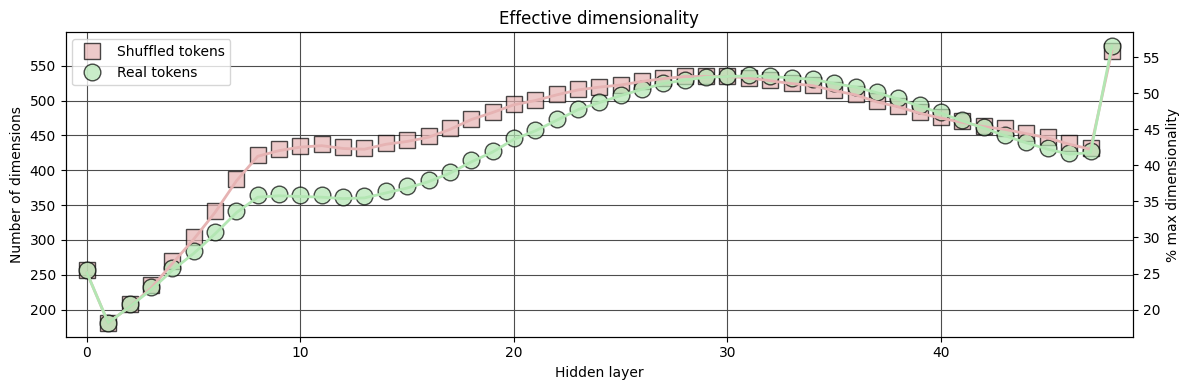

In [61]:

_,ax = plt.subplots(1,figsize=(12,4))

## plot the "effective subspace dimensionality" of each layer
ax.plot(effectiveCompCount[:,1],'ks',markerfacecolor=[.9,.7,.7,.7],markersize=12,label='Shuffled tokens')
ax.plot(effectiveCompCount[:,0],'ko',markerfacecolor=[.7,.9,.7,.7],markersize=12,label='Real tokens')
ax.legend(facecolor='w')
ax.grid(color=[.3,.3,.3])
ax.set(xlabel='Hidden layer',ylabel='Number of dimensions',title='Effective dimensionality',xlim=[-1,numHidden])

ax2 = ax.twinx()
a = 100*effectiveCompCount[:,1] / hs_ranks[:,1]
b = 100*effectiveCompCount[:,0] / hs_ranks[:,0]
ax2.plot(a,linewidth=2,color=[.9,.7,.7])
ax2.plot(b,linewidth=2,color=[.7,.9,.7])
ax2.set(ylabel='% max dimensionality')

plt.tight_layout()
plt.show()


# Part 4: Repeat with Pythia-2.8b

## Task_1:
- Rerun the entire code file with one change: Use the Pythia
2.8b LLM instead of GPT-2-xl. You can access the model via
Hugging Face using EleutherAI/pythia-2.8b. Before rerunning
the code, save screenshots of the GPT-2 results for visual comparison.
Determine whether any of the code or visualization settings
need to be modified for the different model.

In [62]:

### use this cell for Part 4
# from transformers import AutoModelForCausalLM, AutoTokenizer

# tokenizer = AutoTokenizer.from_pretrained('EleutherAI/pythia-2.8b')
# model = AutoModelForCausalLM.from_pretrained('EleutherAI/pythia-2.8b')

# max_seq_len = model.config.max_position_embeddings

# model.to(device)
# model.eval()


# Part 5: Repeat with html code

## Task_1:
- Rerun the code file, but instead of importing a book text
from gutenberg.org, import the website itself. That is, import
http://www.gutenberg.org